In [1]:
# Core data handling libraries
import pandas as pd
import numpy as np

# Visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: preprocessing, model selection and metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Consistent plotting style for all charts in this notebook
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
# Load the dataset 
df = pd.read_csv("Dataset-voice.csv")

In [3]:
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [4]:
# Basic shape of the dataset: (rows, columns)
print("Total records:", df.shape[0])
print("Total attributes:", df.shape[1])

Total records: 3168
Total attributes: 21


In [5]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

In [6]:
# Descriptive statistics for every numeric column
df.describe()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
count,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000
mean,0.180907,0.057126,0.185621,0.140456,0.224765,0.084309,3.140168,36.568461,0.895127,0.408216,0.165282,0.180907,0.142807,0.036802,0.258842,0.829211,0.052647,5.047277,4.994630,0.173752
std,0.029918,0.016652,0.036360,0.048680,0.023639,0.042783,4.240529,134.928661,0.044980,0.177521,0.077203,0.029918,0.032304,0.019220,0.030077,0.525205,0.063299,3.521157,3.520039,0.119454
min,0.039363,0.018363,0.010975,0.000229,0.042946,0.014558,0.141735,2.068455,0.738651,0.036876,0.000000,0.039363,0.055565,0.009775,0.103093,0.007812,0.004883,0.007812,0.000000,0.000000
25%,0.163662,0.041954,0.169593,0.111087,0.208747,0.042560,1.649569,5.669547,0.861811,0.258041,0.118016,0.163662,0.116998,0.018223,0.253968,0.419828,0.007812,2.070312,2.044922,0.099766
50%,0.184838,0.059155,0.190032,0.140286,0.225684,0.094280,2.197101,8.318463,0.901767,0.396335,0.186599,0.184838,0.140519,0.046110,0.271186,0.765795,0.023438,4.992188,4.945312,0.139357
75%,0.199146,0.067020,0.210618,0.175939,0.243660,0.114175,2.931694,13.648905,0.928713,0.533676,0.221104,0.199146,0.169581,0.047904,0.277457,1.177166,0.070312,7.007812,6.992188,0.209183
max,0.251124,0.115273,0.261224,0.247347,0.273469,0.252225,34.725453,1309.612887,0.981997,0.842936,0.280000,0.251124,0.237636,0.204082,0.279114,2.957682,0.458984,21.867188,21.843750,0.932374


In [ ]:
## 3. Data Exploration and Analysis

label
male      1584
female    1584
Name: count, dtype: int64


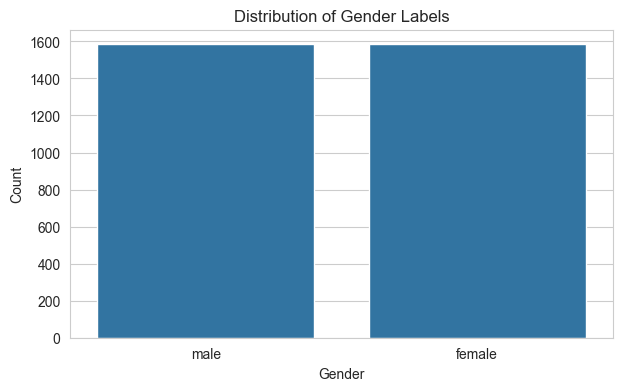

In [7]:
# Class balance of the target variable
print(df["label"].value_counts())

sns.countplot(x="label", data=df)
plt.title("Distribution of Gender Labels")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

In [8]:
# Check for missing (NaN) values and duplicate rows
print("Missing values:\n", df.isnull().sum().sum())
print("Duplicate rows found:", df.duplicated().sum())

Missing values:
 0
Duplicate rows found: 2


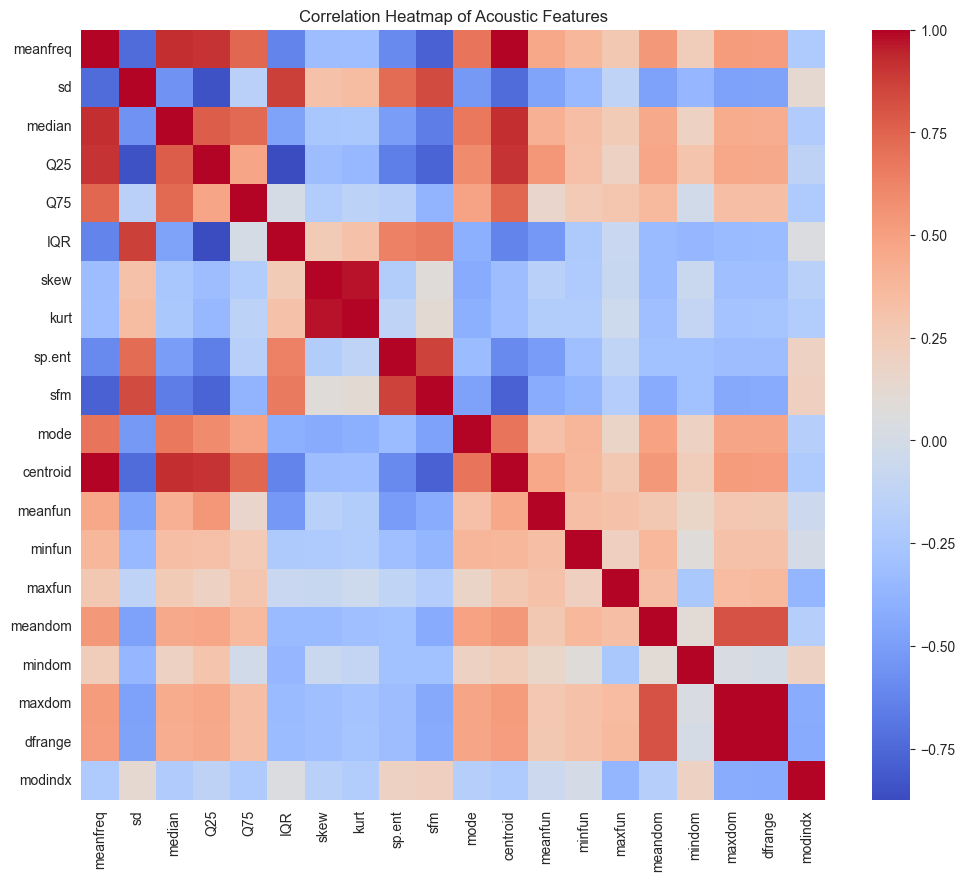

In [9]:
# Correlation heatmap between all numeric acoustic features
plt.figure(figsize=(12, 10))
sns.heatmap(df.drop("label", axis=1).corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap of Acoustic Features")
plt.show()

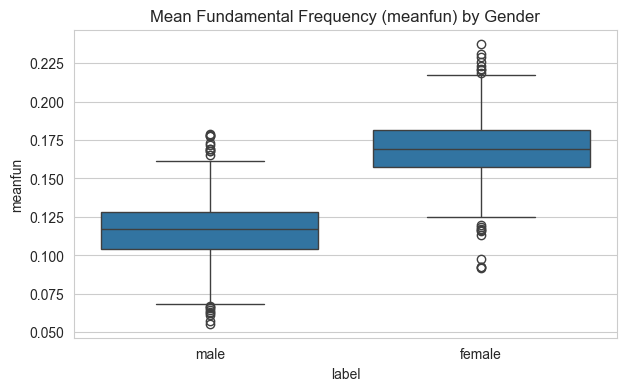

In [10]:
# predictors of gender in speech - visualise it against the label
sns.boxplot(x="label", y="meanfun", data=df)
plt.title("Mean Fundamental Frequency (meanfun) by Gender")
plt.show()

In [ ]:
## 4. Data Preprocessing and Feature Engineering
## 4.1 Removing Duplicates and Encoding the Target

In [11]:
# Step 1: Remove duplicate rows
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (3166, 21)


In [12]:
# Step 2: Encode the target label (female = 0, male = 1)
le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
print("Classes:", list(le.classes_), "-> encoded as", list(le.transform(le.classes_)))

df["label"].value_counts()

Classes: ['female', 'male'] -> encoded as [np.int64(0), np.int64(1)]


label
1    1583
0    1583
Name: count, dtype: int64

In [ ]:
# Feature Selection

In [13]:
# Separate features (X) and target (y)
X = df.drop("label", axis=1)
y = df["label"]

print("Feature set shape:", X.shape)
print("Target shape:", y.shape)

Feature set shape: (3166, 20)
Target shape: (3166,)


In [ ]:
# 4.3 Feature Scaling and Train/Test Split

In [14]:
# Scale the features (mean = 0, standard deviation = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

X_scaled.describe()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
count,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3166.000000,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03,3.166000e+03
mean,-2.513607e-16,3.949953e-16,-7.720363e-16,2.154520e-16,3.052237e-16,3.590867e-16,-4.488583e-18,0.000000,-2.513607e-16,1.077260e-16,-1.077260e-16,-2.513607e-16,3.590867e-16,-1.436347e-16,-1.346575e-15,1.256803e-16,-8.977167e-17,-5.386300e-17,-5.386300e-17,-8.977167e-17
std,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00,1.000158e+00
min,-4.731360e+00,-2.327921e+00,-4.804082e+00,-2.880275e+00,-7.692792e+00,-1.630318e+00,-7.071659e-01,-0.255793,-3.479082e+00,-2.093408e+00,-2.140524e+00,-4.731360e+00,-2.700330e+00,-1.406031e+00,-5.177717e+00,-1.564135e+00,-7.544185e-01,-1.432152e+00,-1.419874e+00,-1.454399e+00
25%,-5.762581e-01,-9.120600e-01,-4.406237e-01,-6.030073e-01,-6.773671e-01,-9.763140e-01,-3.516876e-01,-0.229128,-7.407713e-01,-8.465689e-01,-6.119214e-01,-5.762581e-01,-7.991796e-01,-9.665199e-01,-1.618742e-01,-7.795913e-01,-7.081296e-01,-8.456600e-01,-8.393000e-01,-6.196275e-01
50%,1.313115e-01,1.220336e-01,1.216755e-01,-3.800978e-03,3.892788e-02,2.330810e-01,-2.224122e-01,-0.209409,1.484852e-01,-6.692611e-02,2.756723e-01,1.313115e-01,-6.889445e-02,4.842651e-01,4.105430e-01,-1.204801e-01,-4.612553e-01,-1.479584e-02,-1.316340e-02,-2.878952e-01
75%,6.095155e-01,5.940391e-01,6.876452e-01,7.290813e-01,7.993846e-01,6.979478e-01,-4.913064e-02,-0.169972,7.463863e-01,7.069482e-01,7.230886e-01,6.095155e-01,8.293234e-01,5.776335e-01,6.189955e-01,6.628655e-01,2.793677e-01,5.578117e-01,5.690768e-01,2.962392e-01
max,2.348158e+00,3.491440e+00,2.080751e+00,2.196129e+00,2.061613e+00,3.924838e+00,7.447259e+00,9.433460,1.930872e+00,2.449096e+00,1.486432e+00,2.348158e+00,2.934960e+00,8.702773e+00,6.740915e-01,4.055453e+00,6.420367e+00,4.783778e+00,4.793652e+00,6.350143e+00


In [15]:
# Split into 70% training and 30% testing data (stratified on label)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (2216, 20)
Testing set size: (950, 20)


In [ ]:
# 5. Model Building and Testing

In [16]:
# Helper function: train a model, test it, and collect its evaluation metrics
results = []

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)

    results.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1})

    print(f"--- {name} ---")
    print(f"Accuracy:  {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall:    {rec:.3f}")
    print(f"F1-Score:  {f1:.3f}")

    cm = confusion_matrix(y_te, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Female", "Male"]).plot(cmap="Blues")
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

    print(classification_report(y_te, y_pred, target_names=["Female", "Male"]))
    return model

In [ ]:
# Decision Tree

--- Decision Tree ---
Accuracy:  0.962
Precision: 0.962
Recall:    0.962
F1-Score:  0.962


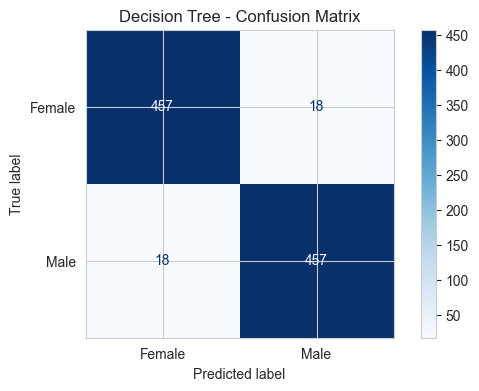

              precision    recall  f1-score   support

      Female       0.96      0.96      0.96       475
        Male       0.96      0.96      0.96       475

    accuracy                           0.96       950
   macro avg       0.96      0.96      0.96       950
weighted avg       0.96      0.96      0.96       950



In [17]:
dt_model = DecisionTreeClassifier(criterion="entropy", max_depth=6, random_state=42)
dt_model = evaluate_model("Decision Tree", dt_model, X_train, X_test, y_train, y_test)

In [ ]:
# Random Forest

--- Random Forest ---
Accuracy:  0.980
Precision: 0.983
Recall:    0.977
F1-Score:  0.980


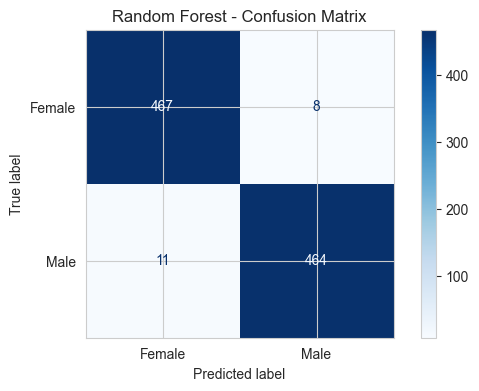

              precision    recall  f1-score   support

      Female       0.98      0.98      0.98       475
        Male       0.98      0.98      0.98       475

    accuracy                           0.98       950
   macro avg       0.98      0.98      0.98       950
weighted avg       0.98      0.98      0.98       950



In [18]:
rf_model = RandomForestClassifier(n_estimators=200, criterion="entropy", random_state=42)
rf_model = evaluate_model("Random Forest", rf_model, X_train, X_test, y_train, y_test)

In [ ]:
# Naïve Bayes

--- Naive Bayes ---
Accuracy:  0.900
Precision: 0.894
Recall:    0.907
F1-Score:  0.901


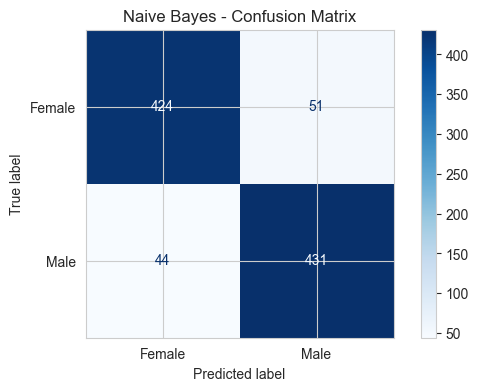

              precision    recall  f1-score   support

      Female       0.91      0.89      0.90       475
        Male       0.89      0.91      0.90       475

    accuracy                           0.90       950
   macro avg       0.90      0.90      0.90       950
weighted avg       0.90      0.90      0.90       950



In [19]:
nb_model = GaussianNB()
nb_model = evaluate_model("Naive Bayes", nb_model, X_train, X_test, y_train, y_test)

In [ ]:
#  Multilayer Artificial Neural Network (Deep Learning)

--- Multilayer ANN ---
Accuracy:  0.980
Precision: 0.987
Recall:    0.973
F1-Score:  0.980


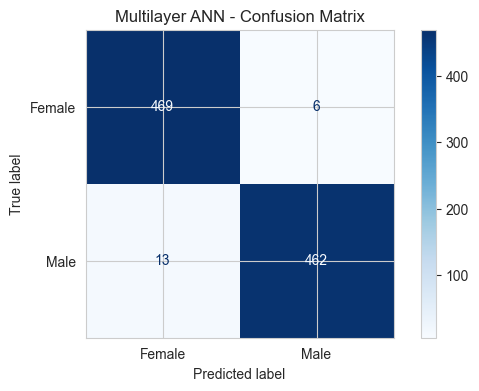

              precision    recall  f1-score   support

      Female       0.97      0.99      0.98       475
        Male       0.99      0.97      0.98       475

    accuracy                           0.98       950
   macro avg       0.98      0.98      0.98       950
weighted avg       0.98      0.98      0.98       950



In [20]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42,
)
mlp_model = evaluate_model("Multilayer ANN", mlp_model, X_train, X_test, y_train, y_test)

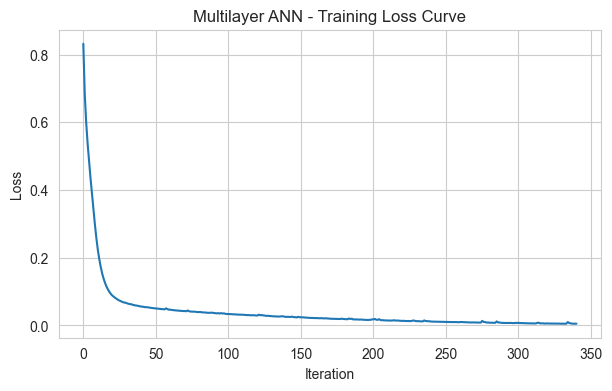

In [21]:
# Visualise the ANN's training loss curve to confirm it converged
plt.plot(mlp_model.loss_curve_)
plt.title("Multilayer ANN - Training Loss Curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [ ]:
## Model Performance Comparison

In [22]:
# Summarise all model metrics in one table
results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.980000,0.983051,0.976842,0.979937
1,Multilayer ANN,0.980000,0.987179,0.972632,0.979852
2,Decision Tree,0.962105,0.962105,0.962105,0.962105
3,Naive Bayes,0.900000,0.894191,0.907368,0.900731


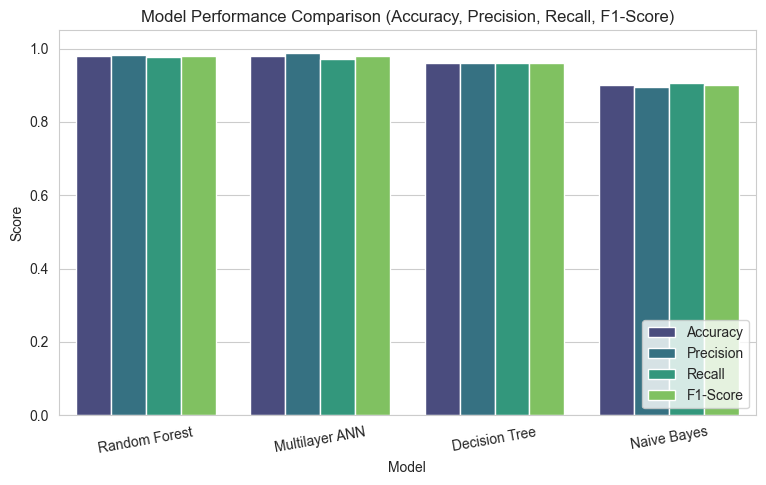

In [23]:
# Grouped bar chart comparing all four metrics across all four models
results_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(9, 5))
sns.barplot(x="Model", y="Score", hue="Metric", data=results_melted, palette="viridis")
plt.ylim(0, 1.05)
plt.title("Model Performance Comparison (Accuracy, Precision, Recall, F1-Score)")
plt.legend(loc="lower right")
plt.xticks(rotation=10)
plt.show()

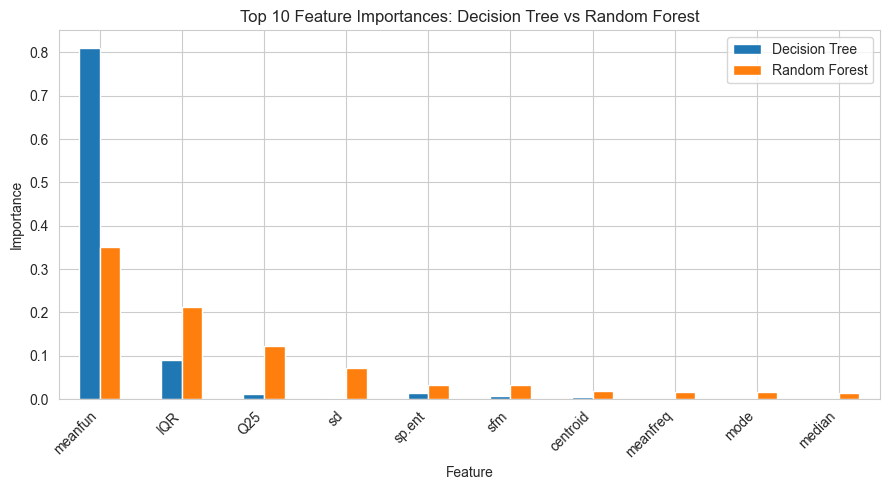

In [24]:
# Feature importance comparison: Decision Tree vs Random Forest
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Decision Tree": dt_model.feature_importances_,
    "Random Forest": rf_model.feature_importances_,
}).sort_values(by="Random Forest", ascending=False).head(10)

importance_df.set_index("Feature").plot(kind="bar", figsize=(9, 5))
plt.title("Top 10 Feature Importances: Decision Tree vs Random Forest")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()